In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/rwanda_basic_needs.csv")
df.head()

,province,district,urban_rural,poverty_status,wealth_quintile,dwelling_type,occupancy_status,dwelling_year,water_source,water_maintenance_cost,lighting_source,basic_servive_index
0,3,36,2,3,4,1,1,6,7,0,11,20.02
1,5,51,2,3,5,1,1,12,2,0,1,79.20
2,5,52,2,3,4,1,1,6,7,0,10,21.66
3,2,21,2,3,3,1,1,17,7,0,11,30.78
4,1,12,1,3,4,6,1,1,3,0,1,24.00


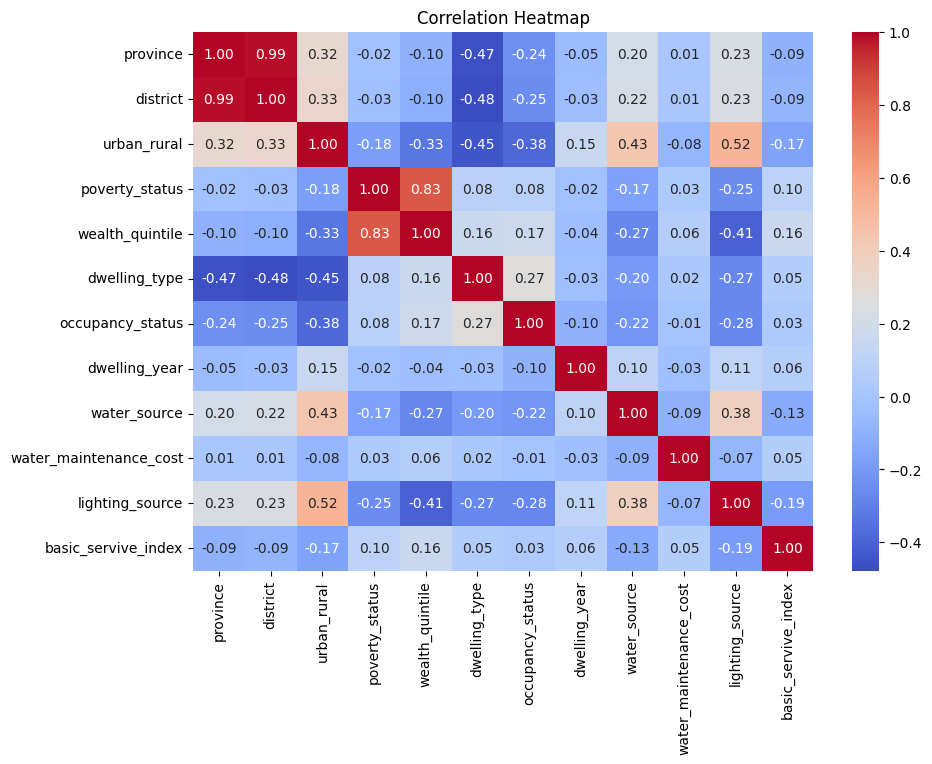

In [13]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

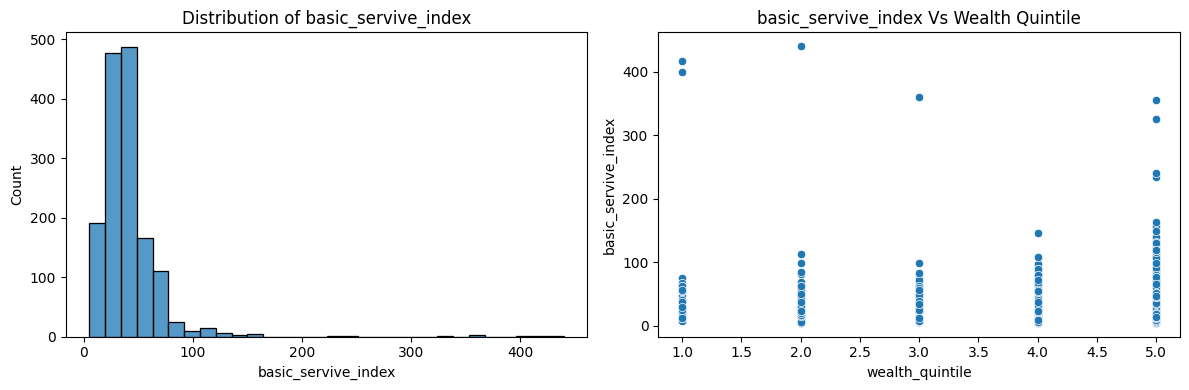

In [17]:
target = df.columns[-1]

fig, axes = plt.subplots(1,2, figsize=(12, 4))

sns.histplot(df[target], bins=30, ax=axes[0])
axes[0].set_title(f"Distribution of {target}")

sns.scatterplot(data=df, x="wealth_quintile", y=target, ax=axes[1])
axes[1].set_title(f"{target} Vs Wealth Quintile")

plt.tight_layout()
plt.show()

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import joblib

target = df.columns[-1]
X = df.drop(columns=[target])
Y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,Y, test_size=0.2, random_state=42
)

num_cols = ["dwelling_year", "water_maintenance_cost"]
cat_cols = [c for c in X.columns if c not in num_cols]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

In [27]:
models = {
    "SGDRegressor": SGDRegressor(max_iter=1000, random_state=42),
    "LinearRegression": LinearRegression(),
    "DecisionTreeRegressor": DecisionTreeRegressor(max_depth=6, random_state=42),
    "RandomForestRegressor": RandomForestRegressor(n_estimators=100, random_state=42)
}

result = {}
best_name = None
best_mse = float("inf")
best_pipeline = None

for name, model in models.items():
  pipe = Pipeline([
      ("prep", preprocessor),
      ("model", model)
  ])
  pipe.fit(X_train, y_train)
  preds = pipe.predict(X_test)
  mse = mean_squared_error(y_test, preds)
  results = {}
  print(f"{name} Test MSE: {mse:.2f}")

  if mse < best_mse:
    best_mse = mse
    best_name = name
    best_pipeline = pipe

print(f"\nBest Mode: {best_name} (Test MSE: {best_mse:.2f})")
joblib.dump(best_pipeline, "best_model.pkl")


SGDRegressor Test MSE: 1026.43
LinearRegression Test MSE: 959.66
DecisionTreeRegressor Test MSE: 2015.33
RandomForestRegressor Test MSE: 1040.80

Best Mode: LinearRegression (Test MSE: 959.66)


['best_model.pkl']

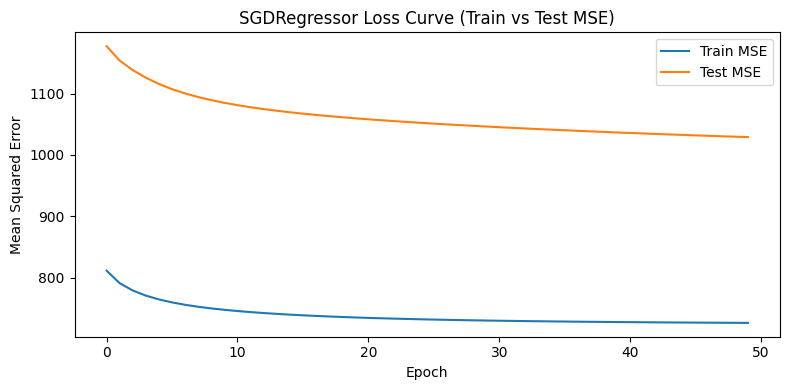

In [32]:
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

sgd = SGDRegressor(learning_rate="constant", eta0=0.005, random_state=42)
train_mse, test_mse = [], []

for epoch in range(50):
  sgd.partial_fit(X_train_prep, y_train)
  train_mse.append(mean_squared_error(y_train, sgd.predict(X_train_prep)))
  test_mse.append(mean_squared_error(y_test, sgd.predict(X_test_prep)))

plt.figure(figsize=(8, 4))
plt.plot(train_mse, label="Train MSE")
plt.plot(test_mse, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("SGDRegressor Loss Curve (Train vs Test MSE)")
plt.legend()
plt.tight_layout()
plt.show()

The blue and orange lines they both drop quickly during the first few epochs and then flatten out. Where this shows that the model learns the pattern steadily without overfitting.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


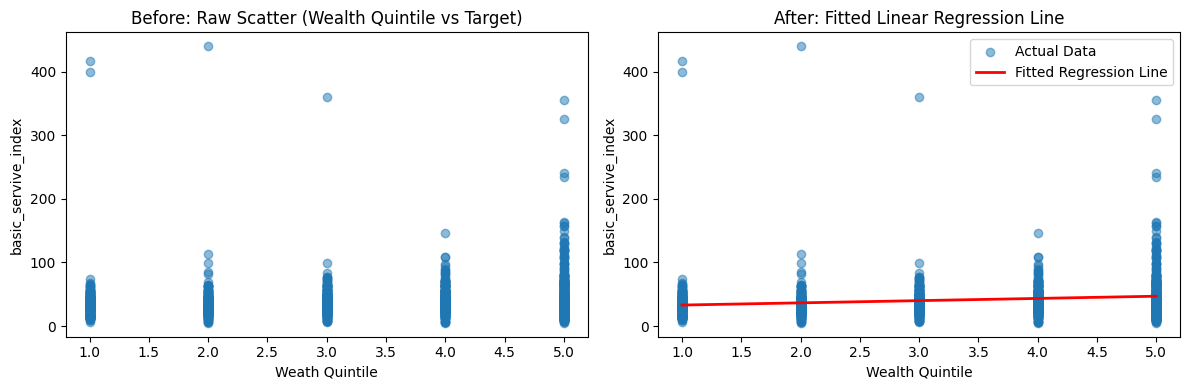

In [33]:
import numpy as np
feat = "wealth_quintile"
x_single = df[[feat]]
y_single = df[target]

line_model = LinearRegression()
line_model.fit(x_single, y_single)
x_grid = np.linspace(x_single.min().values[0], x_single.max().values[0], 100).reshape(-1, 1)
y_line = line_model.predict(x_grid)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(x_single, y_single, alpha=0.5)
axes[0].set_title("Before: Raw Scatter (Wealth Quintile vs Target)")
axes[0].set_xlabel("Weath Quintile")
axes[0].set_ylabel(target)

axes[1].scatter(x_single, y_single, alpha=0.5, label="Actual Data")
axes[1].plot(x_grid, y_line, color="red", linewidth=2, label="Fitted Regression Line")
axes[1].set_title("After: Fitted Linear Regression Line")
axes[1].set_xlabel("Wealth Quintile")
axes[1].set_ylabel(target)
axes[1].legend()

plt.tight_layout()
plt.show()

On the left there's household data accross wealth quintiles, and on the right the red regression line shows a slight upward trend as wealth quintile increases.